# SESSION 11 - Data Visualization: Matplotlib (Part 2)

**Curriculum Module:** Data Collection, Cleaning, Visualization and Analysis  
**Session:** 11 - Data Visualization: Matplotlib (Part 2)  
**Status:** ✅ Completed

---

## 📋 Topics Covered
1. **Subplots Grid (`plt.subplots()`)**: Constructing structured 2x2 multi-panel layouts combining disparate chart types (Line, Bar, Scatter, Pie).
2. **Advanced Plot & Edge Styling**: Applying nuanced aesthetics via `linestyle` (`'--'`, `'-.'`, `':'`), `linewidth`, and edge color contrasts.
3. **Multi-Axis Visualizations (`ax.twinx()`)**: Synchronizing heterogeneous metrics with differing magnitudes (Follower count in Millions vs. Daily posts) on twin y-axes.
4. **Categorical vs. Numeric Bivariate Scatter**: Mapping categorical entities alongside numerical continuous scales with dynamic text placement.
5. **Chart Annotations & Callouts (`ax.annotate()`)**: Pinpointing pivotal business inflection points with custom callout boxes and directional vector arrows.


---

## Task 1: 2x2 Grid of Subplots (Line, Bar, Scatter, Pie)

**Problem Statement:**  
*Use `plt.subplots()` to create a 2x2 grid of subplots and plot four different types of charts (line, bar, scatter, and pie) using any sample data of your choice.*


Sample Multi-Metric Dataset:
  month  web_traffic_thousands product_category  category_sales_lakhs  ad_spend_thousands  conversions  browser  browser_market_share
0   Jan                    120      Electronics                    45                  15          320   Chrome                    65
1   Feb                    145          Fashion                    38                  20          410   Safari                    18
2   Mar                    180   Home & Kitchen                    25                  25          540     Edge                     9
3   Apr                    210     Books & Toys                    18                  30          680  Firefox                     5
4   May                    260           Beauty                    30                  35          820   Others                     3


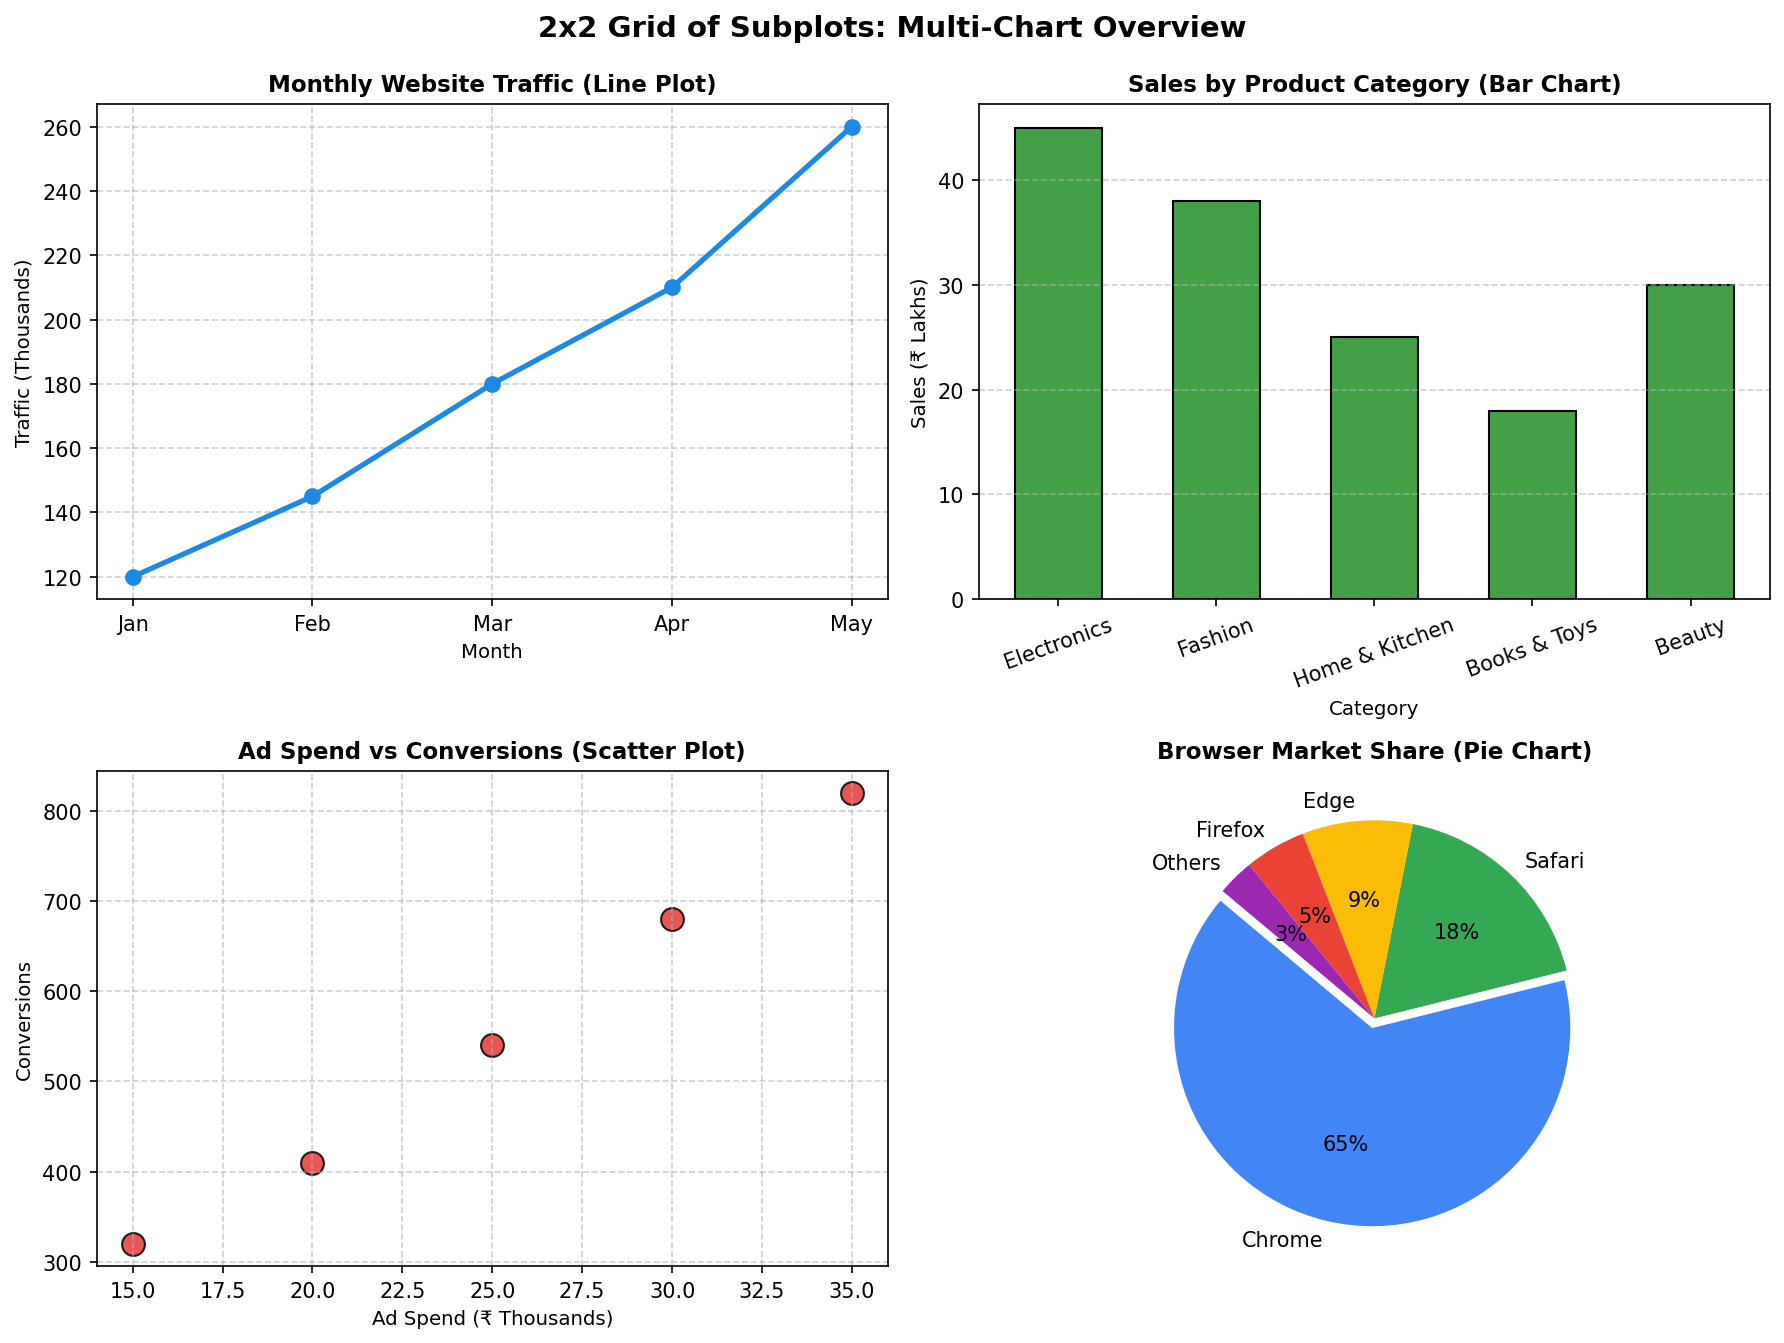

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

# Load sample multi-metric business dataset
df_sample = pd.read_csv('four_charts_sample.csv')
print('Sample Multi-Metric Dataset:')
print(df_sample)

# Create 2x2 subplot canvas
fig, axs = plt.subplots(2, 2, figsize=(12, 9), dpi=150)

# [0, 0] Line Plot: Monthly Web Traffic
axs[0, 0].plot(df_sample['month'], df_sample['web_traffic_thousands'], marker='o', color='#1E88E5', linewidth=2.5, markersize=7)
axs[0, 0].set_title('Monthly Website Traffic (Line Plot)', fontsize=11, fontweight='bold')
axs[0, 0].set_xlabel('Month', fontsize=9.5)
axs[0, 0].set_ylabel('Traffic (Thousands)', fontsize=9.5)
axs[0, 0].grid(True, linestyle='--', alpha=0.6)

# [0, 1] Bar Chart: Category Sales
axs[0, 1].bar(df_sample['product_category'], df_sample['category_sales_lakhs'], color='#43A047', edgecolor='black', width=0.55)
axs[0, 1].set_title('Sales by Product Category (Bar Chart)', fontsize=11, fontweight='bold')
axs[0, 1].set_xlabel('Category', fontsize=9.5)
axs[0, 1].set_ylabel('Sales (₹ Lakhs)', fontsize=9.5)
axs[0, 1].tick_params(axis='x', rotation=20)
axs[0, 1].grid(axis='y', linestyle='--', alpha=0.6)

# [1, 0] Scatter Plot: Ad Spend vs Conversions
axs[1, 0].scatter(df_sample['ad_spend_thousands'], df_sample['conversions'], color='#E53935', s=120, edgecolor='black', alpha=0.85)
axs[1, 0].set_title('Ad Spend vs Conversions (Scatter Plot)', fontsize=11, fontweight='bold')
axs[1, 0].set_xlabel('Ad Spend (₹ Thousands)', fontsize=9.5)
axs[1, 0].set_ylabel('Conversions', fontsize=9.5)
axs[1, 0].grid(True, linestyle='--', alpha=0.6)

# [1, 1] Pie Chart: Browser Market Share
pie_colors = ['#4285F4', '#34A853', '#FBBC05', '#EA4335', '#9C27B0']
axs[1, 1].pie(df_sample['browser_market_share'], labels=df_sample['browser'], autopct='%1.0f%%', startangle=140, colors=pie_colors, explode=(0.05, 0, 0, 0, 0))
axs[1, 1].set_title('Browser Market Share (Pie Chart)', fontsize=11, fontweight='bold')

fig.suptitle('2x2 Grid of Subplots: Multi-Chart Overview', fontsize=14, fontweight='bold', y=0.99)
fig.tight_layout()
plt.savefig('grid_2x2_charts.png', bbox_inches='tight')
plt.show()


---

## Task 2: Delivery Time Bar Chart with Custom Linestyles & Linewidths

**Problem Statement:**  
*Plot a comparison of average delivery times for Zomato, Swiggy, and Domino's using a bar chart, and style each bar with a different color, linestyle, and linewidth using Matplotlib plot styling options.*


Delivery Times Dataset:
   platform  avg_delivery_time_mins    color edge_color linestyle  linewidth
0    Zomato                      32  #FFCDD2    #D32F2F        --        2.5
1    Swiggy                      28  #FFE0B2    #E65100        -.        3.0
2  Domino's                      22  #BBDEFB    #0D47A1         :        3.5


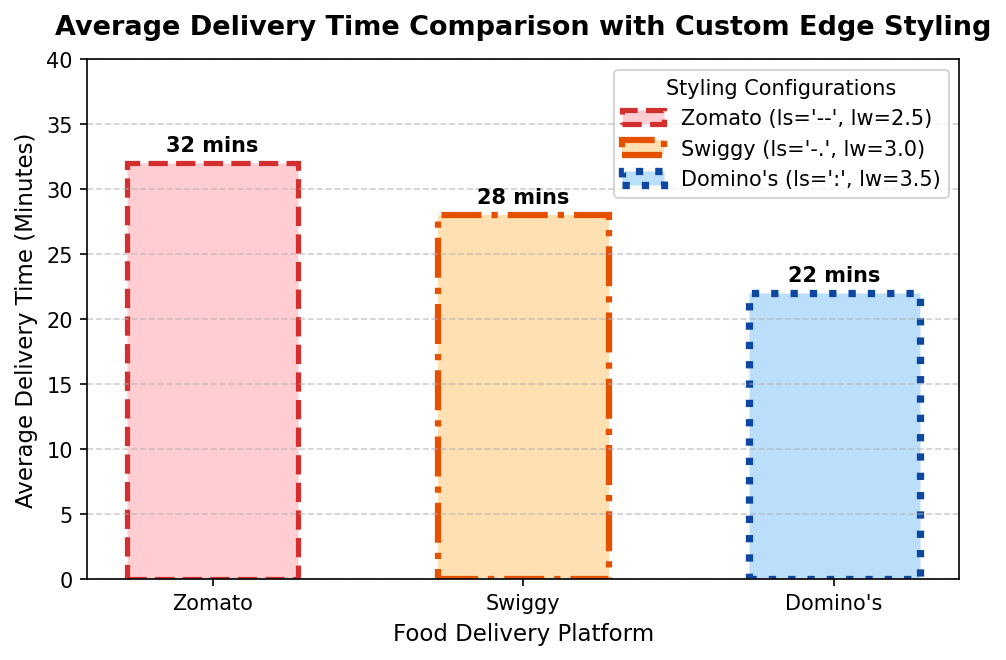

In [2]:
# Load delivery times dataset
df_delivery = pd.read_csv('delivery_times.csv')
print('Delivery Times Dataset:')
print(df_delivery)

# Create Bar Chart with custom edge styling
fig, ax = plt.subplots(figsize=(7.5, 4.5), dpi=150)
bars = ax.bar(
    df_delivery['platform'],
    df_delivery['avg_delivery_time_mins'],
    color=df_delivery['color'],
    edgecolor=df_delivery['edge_color'],
    width=0.55
)

# Iterate to apply individual linestyles, linewidths, and labels
for bar, row in zip(bars, df_delivery.itertuples()):
    bar.set_linestyle(row.linestyle)
    bar.set_linewidth(row.linewidth)
    bar.set_label(f"{row.platform} (ls='{row.linestyle}', lw={row.linewidth})")
    yval = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2.0, yval + 0.6, f"{int(yval)} mins", ha='center', va='bottom', fontweight='bold', fontsize=10)

ax.set_title('Average Delivery Time Comparison with Custom Edge Styling', fontsize=13, fontweight='bold', pad=12)
ax.set_xlabel('Food Delivery Platform', fontsize=11)
ax.set_ylabel('Average Delivery Time (Minutes)', fontsize=11)
ax.set_ylim(0, 40)
ax.grid(axis='y', linestyle='--', alpha=0.6)
ax.legend(title='Styling Configurations', loc='upper right')

plt.savefig('delivery_time_comparison.png', bbox_inches='tight')
plt.show()


---

## Task 3: Multi-Axis Chart (Instagram Followers vs. Daily Posts)

**Problem Statement:**  
*Create a multi-axis chart that shows the number of Instagram followers (left y-axis) and average daily posts (right y-axis) for five influencers. Use different colors and markers for each axis.*


Influencer Metrics Data:
      influencer_name  followers_millions  avg_daily_posts          genre
0         Virat Kohli               270.0              1.2         Sports
1     Kritika Khurana                 1.8              4.5        Fashion
2          Bhuvan Bam                19.5              0.8         Comedy
3  Ranveer Allahbadia                 9.2              3.2       Podcasts
4        Kusha Kapila                 3.6              2.8  Entertainment


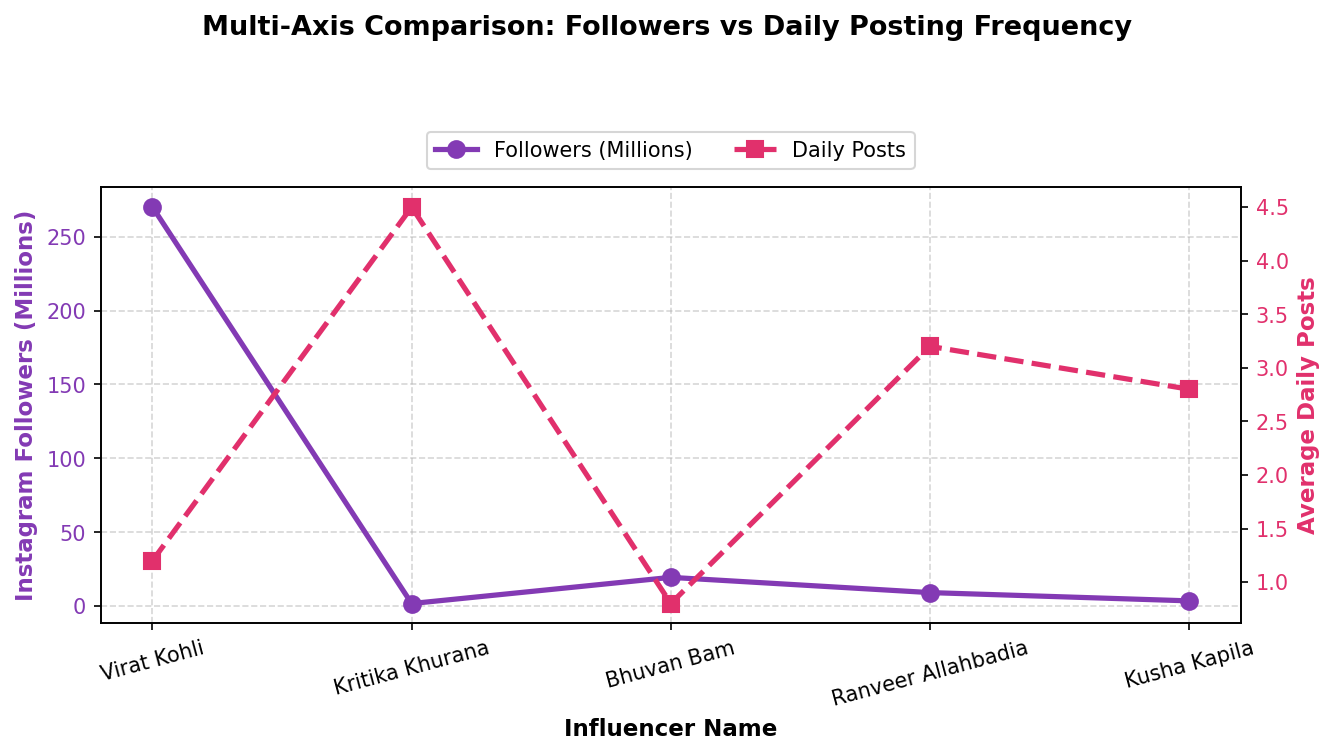

In [3]:
# Load influencer metrics dataset
df_influencers = pd.read_csv('influencers_metrics.csv')
print('Influencer Metrics Data:')
print(df_influencers)

fig, ax1 = plt.subplots(figsize=(9, 4.8), dpi=150)

# Primary Y-Axis (Left): Instagram Followers
color1 = '#833AB4'
ax1.set_xlabel('Influencer Name', fontsize=11, fontweight='bold')
ax1.set_ylabel('Instagram Followers (Millions)', color=color1, fontsize=11, fontweight='bold')
line1 = ax1.plot(
    df_influencers['influencer_name'],
    df_influencers['followers_millions'],
    color=color1,
    marker='o',
    linewidth=2.5,
    markersize=8,
    label='Followers (Millions)'
)
ax1.tick_params(axis='y', labelcolor=color1)
ax1.tick_params(axis='x', rotation=15)
ax1.grid(True, linestyle='--', alpha=0.5)

# Secondary Y-Axis (Right): Average Daily Posts
ax2 = ax1.twinx()
color2 = '#E1306C'
ax2.set_ylabel('Average Daily Posts', color=color2, fontsize=11, fontweight='bold')
line2 = ax2.plot(
    df_influencers['influencer_name'],
    df_influencers['avg_daily_posts'],
    color=color2,
    marker='s',
    linewidth=2.5,
    markersize=8,
    linestyle='--',
    label='Daily Posts'
)
ax2.tick_params(axis='y', labelcolor=color2)

# Synchronized Legend across twin axes
lines = line1 + line2
labels = [l.get_label() for l in lines]
ax1.legend(lines, labels, loc='upper center', bbox_to_anchor=(0.5, 1.15), ncol=2, frameon=True)

fig.suptitle('Multi-Axis Comparison: Followers vs Daily Posting Frequency', fontsize=13, fontweight='bold', y=1.04)
fig.tight_layout()
plt.savefig('influencers_dual_axis.png', bbox_inches='tight')
plt.show()


---

## Task 4: Categorical vs Numeric Scatter Plot with Text Annotations

**Problem Statement:**  
*Plot the number of tickets sold for five recent Bollywood movies (categorical) versus their IMDb ratings (numeric) using a scatter plot. Add annotations to display the movie names above each point.*


Bollywood Movies Data:
  movie_title  imdb_rating  tickets_sold_thousands  box_office_crores
0       Jawan          7.0                   14200               1148
1      Animal          6.2                   11500                917
2     Stree 2          7.3                   12800                874
3   12th Fail          8.9                    3200                 69
4     Fighter          6.5                    6800                337


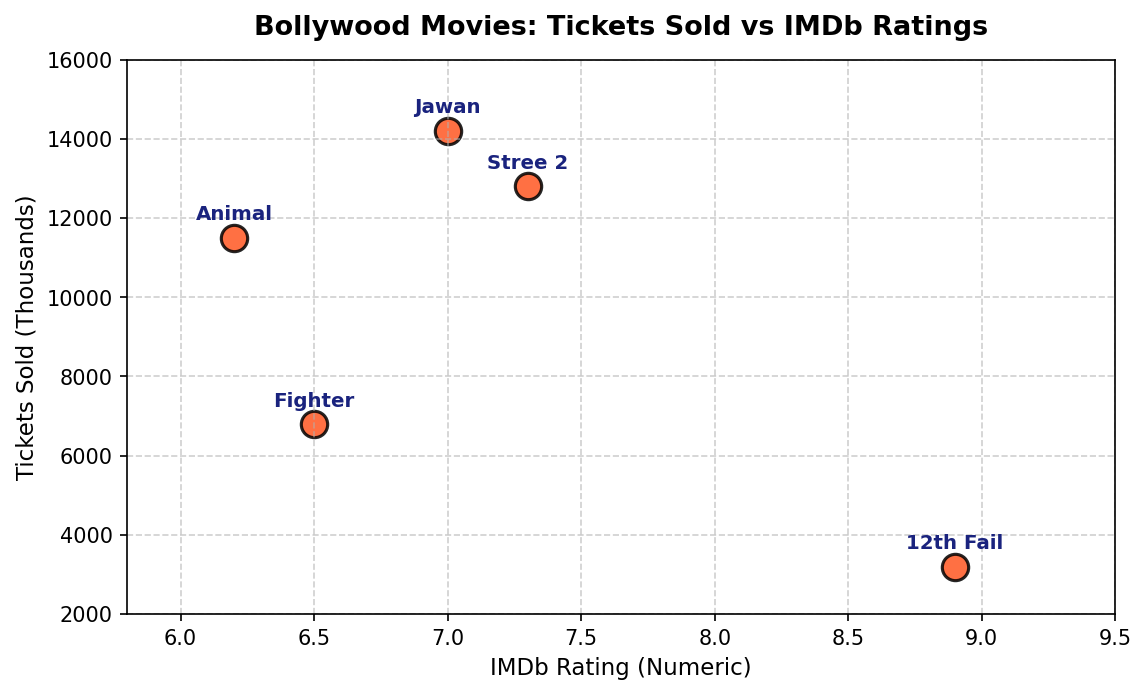

In [4]:
# Load Bollywood movies dataset
df_movies = pd.read_csv('bollywood_movies.csv')
print('Bollywood Movies Data:')
print(df_movies)

# Create scatter plot of tickets sold vs IMDb rating
fig, ax = plt.subplots(figsize=(8.5, 4.8), dpi=150)
ax.scatter(
    df_movies['imdb_rating'],
    df_movies['tickets_sold_thousands'],
    color='#FF5722',
    s=160,
    edgecolor='black',
    linewidth=1.5,
    alpha=0.85,
    label='Movies'
)

# Add text annotations above each point
for i, row in df_movies.iterrows():
    ax.annotate(
        row['movie_title'],
        (row['imdb_rating'], row['tickets_sold_thousands'] + 450),
        ha='center',
        fontsize=9.5,
        fontweight='bold',
        color='#1A237E'
    )

ax.set_title('Bollywood Movies: Tickets Sold vs IMDb Ratings', fontsize=13, fontweight='bold', pad=12)
ax.set_xlabel('IMDb Rating (Numeric)', fontsize=11)
ax.set_ylabel('Tickets Sold (Thousands)', fontsize=11)
ax.set_xlim(5.8, 9.5)
ax.set_ylim(2000, 16000)
ax.grid(True, linestyle='--', alpha=0.6)
plt.savefig('bollywood_tickets_vs_rating.png', bbox_inches='tight')
plt.show()


---

## Task 5: Custom Callout Annotation with Arrow ('Big Billion Days')

**Problem Statement:**  
*Add a custom text annotation to a Matplotlib chart showing Flipkart's monthly sales, marking the highest sales point with the label 'Big Billion Days'.*  
*Hint: Use the `ax.annotate()` function to place the label at the correct data point.*


Flipkart Monthly Gross Sales (12 Months):
   month_name  month_num  sales_crores
0         Jan          1           420
1         Feb          2           460
2         Mar          3           510
3         Apr          4           490
4         May          5           530
5         Jun          6           580
6         Jul          7           610
7         Aug          8           640
8         Sep          9           720
9         Oct         10          1850
10        Nov         11           920
11        Dec         12           780


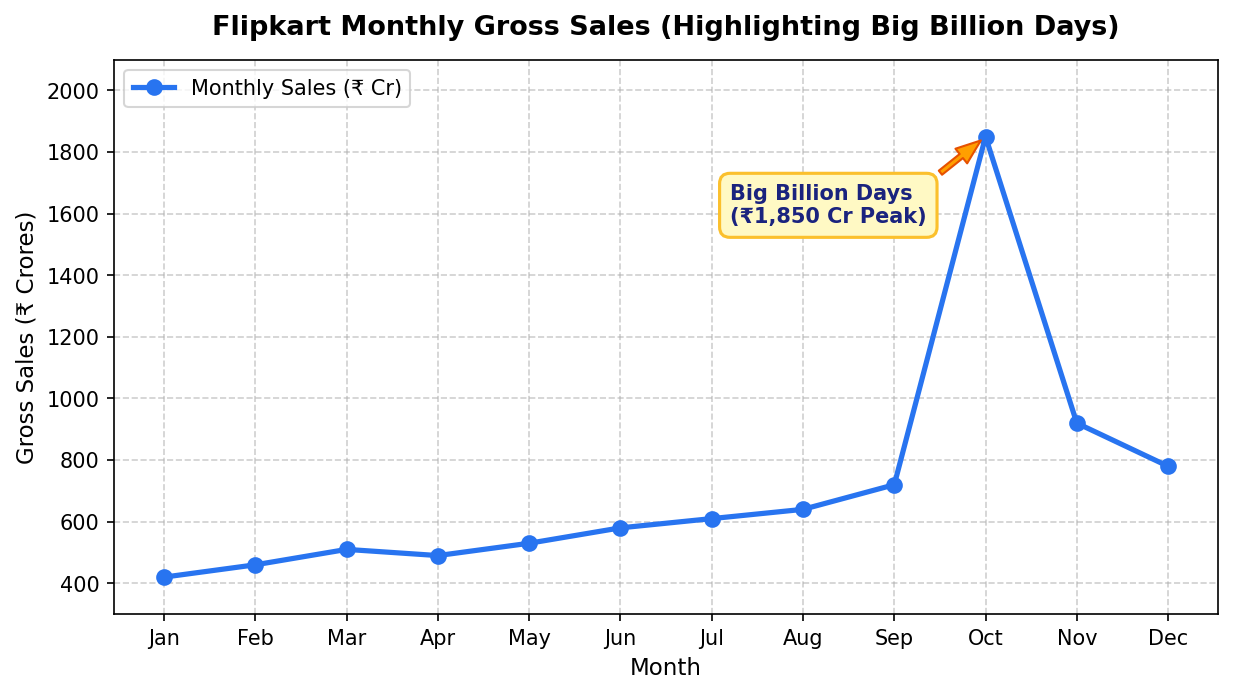

In [5]:
# Load Flipkart monthly sales dataset
df_sales = pd.read_csv('flipkart_monthly_sales.csv')
print('Flipkart Monthly Gross Sales (12 Months):')
print(df_sales)

# Create line plot of sales across 12 months
fig, ax = plt.subplots(figsize=(9.5, 4.8), dpi=150)
ax.plot(
    df_sales['month_name'],
    df_sales['sales_crores'],
    marker='o',
    color='#2874F0',
    linewidth=2.5,
    markersize=7,
    label='Monthly Sales (₹ Cr)'
)

# Identify peak sales record (October Big Billion Days)
oct_idx = df_sales[df_sales['month_name'] == 'Oct'].index[0]
oct_sales = df_sales.loc[oct_idx, 'sales_crores']

# Add directional arrow annotation calling out 'Big Billion Days'
ax.annotate(
    'Big Billion Days\n(₹1,850 Cr Peak)',
    xy=(oct_idx, oct_sales),
    xytext=(oct_idx - 2.8, oct_sales - 280),
    arrowprops=dict(facecolor='#FF9F00', shrink=0.08, width=2.5, headwidth=9, edgecolor='#E65100'),
    fontsize=10,
    fontweight='bold',
    color='#1A237E',
    bbox=dict(boxstyle='round,pad=0.5', facecolor='#FFF9C4', edgecolor='#FBC02D', linewidth=1.5)
)

ax.set_title('Flipkart Monthly Gross Sales (Highlighting Big Billion Days)', fontsize=13, fontweight='bold', pad=12)
ax.set_xlabel('Month', fontsize=11)
ax.set_ylabel('Gross Sales (₹ Crores)', fontsize=11)
ax.set_ylim(300, 2100)
ax.grid(True, linestyle='--', alpha=0.6)
ax.legend(loc='upper left')

plt.savefig('flipkart_sales_annotation.png', bbox_inches='tight')
plt.show()


---

## 🎯 Key Takeaways & Best Practices
- **Structured Dashboard Layouts (`plt.subplots()`)**: 2x2 grids allow comparison across continuous trends (line), categorical distributions (bar), bivariate associations (scatter), and proportional breakdowns (pie).
- **Visual Encoding via Linestyles & Widths**: Beyond color, altering edge borders (`linestyle='--'`, `linewidth=2.5`) provides an accessible visual differentiator for color-blind readers and black-and-white printing.
- **Twin Y-Axes Synchronization (`ax.twinx()`)**: When plotting two metrics with vastly differing scales (e.g., Millions of followers vs. single-digit daily posts), secondary axes prevent flattening of the smaller series.
- **Precision Annotations (`ax.annotate()`)**: Arrow callouts and custom bounding boxes (`bbox=dict(...)`) transform standard charts into explanatory storytelling visual assets for executive presentations.
